# TED 02 — Notebook 03: Análise Exploratória de Dados (EDA)
Pergunta-guia: **o que os dados revelam sobre o problema que o assistente de diagnóstico da Inforcell pretende resolver?**
Todos os números citados no Documento Técnico v2.0 saem deste notebook e são gravados em `reports/resultados_eda.json`.

In [1]:
import sys, json, re
sys.path.insert(0, "../../src")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import preparacao as prep, graficos as g
g.aplicar_estilo()
R = {}  # resultados exportados para o documento
reparos = pd.read_csv(prep.PROCESSED / "reparos_limpo.csv", parse_dates=["data_evento"])
falhas = pd.read_csv(prep.PROCESSED / "falhas_rotuladas_limpo.csv", parse_dates=["data_evento"])
ORD_CAT = ["Notebook", "Celular", "Tablet", "Desktop"]
ORD_ST = ["Consertado", "Reparável (não concluído)", "Fim de vida", "Desconhecido"]
print(reparos.shape, falhas.shape)

(22533, 19) (6657, 20)


## 1. Estatísticas descritivas — Base A

In [2]:
freq = reparos["categoria"].value_counts().reindex(ORD_CAT)
tab_freq = pd.DataFrame({"registros": freq, "%": (freq / freq.sum() * 100).round(1)})
R["freq_categoria"] = tab_freq.reset_index().to_dict("records")
tab_freq

,registros,%
categoria,,
Notebook,12156,53.9
Celular,5188,23.0
Tablet,2818,12.5
Desktop,2371,10.5


In [3]:
st = pd.crosstab(reparos["categoria"], reparos["status_reparo"], normalize="index").reindex(index=ORD_CAT, columns=ORD_ST) * 100
st = st.round(1)
taxa = reparos.groupby("categoria")["consertado"].mean().reindex(ORD_CAT) * 100
st["Taxa de conserto*"] = taxa.round(1)
R["status_categoria"] = st.reset_index().to_dict("records")
R["taxa_conserto_geral"] = round(reparos["consertado"].mean() * 100, 1)
print("* consertados / (total - desconhecidos)  | taxa geral:", R["taxa_conserto_geral"], "%")
st

* consertados / (total - desconhecidos)  | taxa geral: 55.4 %


status_reparo,Consertado,Reparável (não concluído),Fim de vida,Desconhecido,Taxa de conserto*
categoria,,,,,
Notebook,54.8,26.5,15.4,3.3,56.7
Celular,55.0,26.4,15.5,3.0,56.7
Tablet,43.5,30.3,22.0,4.2,45.4
Desktop,54.2,20.6,18.2,7.0,58.3


In [4]:
desc_idade = reparos.groupby("categoria")["idade_anos"].describe().reindex(ORD_CAT)
desc_idade["IQR"] = desc_idade["75%"] - desc_idade["25%"]
desc_idade["assimetria"] = reparos.groupby("categoria")["idade_anos"].apply(lambda s: s.dropna().astype(float).skew()).reindex(ORD_CAT)
desc_idade["moda"] = reparos.groupby("categoria")["idade_anos"].agg(lambda s: s.mode().iloc[0]).reindex(ORD_CAT)
desc_idade = desc_idade.round(2)
geral = reparos["idade_anos"].astype(float).describe()
R["idade_desc"] = desc_idade.reset_index().to_dict("records")
R["idade_geral"] = {k: round(float(v), 2) for k, v in geral.items()}
desc_idade

,count,mean,std,min,25%,50%,75%,max,IQR,assimetria,moda
categoria,,,,,,,,,,,
Notebook,3936.0,7.15,4.09,0.0,4.0,6.0,10.0,35.0,6.0,1.05,5.0
Celular,1494.0,4.80,4.16,0.0,2.0,4.0,6.0,30.0,4.0,2.52,2.0
Tablet,837.0,5.58,3.59,0.0,3.0,5.0,7.0,23.0,4.0,1.36,5.0
Desktop,600.0,9.47,6.40,0.0,5.0,8.0,12.0,41.0,7.0,1.74,10.0


In [5]:
txt = reparos.loc[reparos["tem_descricao"], "n_palavras"]
R["palavras_desc"] = {k: round(float(v), 2) for k, v in txt.describe().items()}
R["pct_ate_5_palavras"] = round(float((txt <= 5).mean() * 100), 1)
print(txt.describe().round(2)); print("% descrições com até 5 palavras:", R["pct_ate_5_palavras"])

count    16982.00
mean         9.56
std         13.59
min          1.00
25%          3.00
50%          6.00
75%         11.00
max        960.00
Name: n_palavras, dtype: float64
% descrições com até 5 palavras: 45.3


In [6]:
idi = reparos["idioma"].value_counts()
R["idiomas"] = (idi / idi.sum() * 100).round(1).to_dict()
(idi / idi.sum() * 100).round(1).to_frame("% dos registros")

,% dos registros
idioma,
en,39.0
sem texto,24.6
de,11.1
fr,9.5
nl,9.1
indefinido,4.3
no,1.3
it,0.6
es,0.4


## 2. Distribuições — desfecho, idade e texto

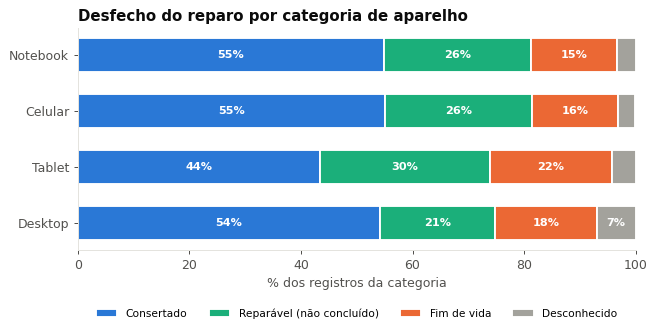

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig02_status_categoria.png')

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
esq = np.zeros(len(ORD_CAT))
for s in ORD_ST:
    v = st[s].values
    ax.barh(ORD_CAT, v, left=esq, color=g.COR_STATUS[s], height=0.6, label=s, edgecolor="white", linewidth=1.5)
    for i, (l, w) in enumerate(zip(esq, v)):
        if w >= 7: ax.text(l + w/2, i, f"{w:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    esq += v
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% dos registros da categoria"); ax.grid(False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=8.5)
ax.set_title("Desfecho do reparo por categoria de aparelho")
g.salvar(fig, "fig02_status_categoria")

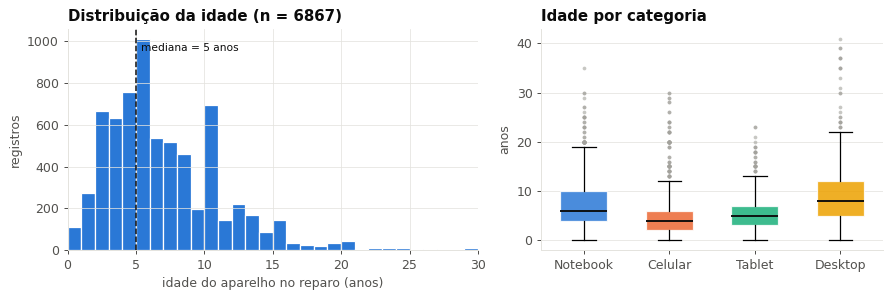

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig03_idade.png')

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [1.2, 1]})
ida = reparos.dropna(subset=["idade_anos"])
axs[0].hist(ida["idade_anos"], bins=range(0, 31), color=g.SERIES[0], edgecolor="white", linewidth=1)
axs[0].axvline(ida["idade_anos"].median(), color=g.TXT, lw=1.2, ls="--")
axs[0].text(ida["idade_anos"].median() + .4, axs[0].get_ylim()[1]*.9, f"mediana = {ida['idade_anos'].median():.0f} anos", fontsize=8.5, color=g.TXT)
axs[0].set_xlim(0, 30); axs[0].set_xlabel("idade do aparelho no reparo (anos)"); axs[0].set_ylabel("registros")
axs[0].set_title("Distribuição da idade (n = %d)" % len(ida))
dados = [ida.loc[ida["categoria"] == c, "idade_anos"].astype(float) for c in ORD_CAT]
bp = axs[1].boxplot(dados, tick_labels=ORD_CAT, patch_artist=True, widths=.55, showfliers=True,
                    flierprops=dict(marker="o", markersize=3, markerfacecolor=g.CINZA, markeredgecolor="none", alpha=.6),
                    medianprops=dict(color=g.TXT, lw=1.5))
for p, c in zip(bp["boxes"], ORD_CAT): p.set_facecolor(g.COR_CATEGORIA[c]); p.set_alpha(.85); p.set_edgecolor("white")
axs[1].set_ylabel("anos"); axs[1].set_title("Idade por categoria"); axs[1].grid(axis="x", visible=False)
fig.tight_layout(); g.salvar(fig, "fig03_idade")

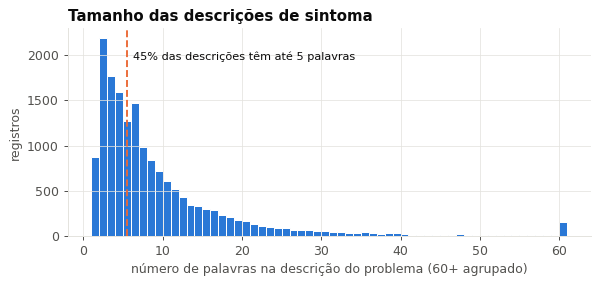

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig04_palavras.png')

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.hist(txt.clip(upper=60), bins=range(1, 62), color=g.SERIES[0], edgecolor="white", linewidth=.8)
ax.axvline(5.5, color=g.SERIES[1], lw=1.5, ls="--")
ax.text(6.3, ax.get_ylim()[1]*.85, f"{R['pct_ate_5_palavras']:.0f}% das descrições têm até 5 palavras", color=g.TXT, fontsize=9)
ax.set_xlabel("número de palavras na descrição do problema (60+ agrupado)"); ax.set_ylabel("registros")
ax.set_title("Tamanho das descrições de sintoma"); g.salvar(fig, "fig04_palavras")

## 3. Tendência temporal

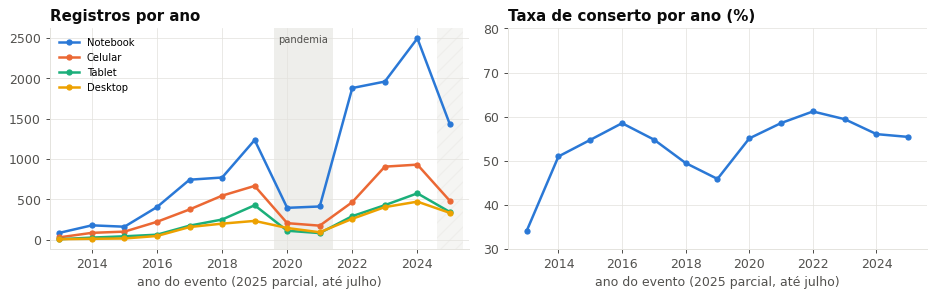

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig05_serie_temporal.png')

In [10]:
anual = reparos[reparos["ano_evento"].between(2013, 2025)].pivot_table(index="ano_evento", columns="categoria", values="id", aggfunc="count").reindex(columns=ORD_CAT)
taxa_ano = reparos[reparos["ano_evento"].between(2013, 2025)].groupby("ano_evento")["consertado"].mean() * 100
R["anual"] = anual.fillna(0).astype(int).reset_index().to_dict("records")
R["taxa_ano"] = taxa_ano.round(1).to_dict()
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.4))
for c in ORD_CAT:
    axs[0].plot(anual.index, anual[c], marker="o", markersize=4, color=g.COR_CATEGORIA[c], label=c)
axs[0].axvspan(2019.6, 2021.4, color=g.GRADE, alpha=.6, lw=0); axs[0].text(2020.5, axs[0].get_ylim()[1]*.93, "pandemia", ha="center", fontsize=8, color=g.TXT2)
axs[0].axvspan(2024.6, 2025.4, color=g.GRADE, alpha=.35, lw=0, hatch="//")
axs[0].set_title("Registros por ano"); axs[0].set_xlim(2012.7, 2025.6); axs[0].legend(fontsize=8, loc="upper left")
axs[1].plot(taxa_ano.index, taxa_ano.values, marker="o", markersize=4, color=g.SERIES[0])
axs[1].set_ylim(30, 80); axs[1].set_title("Taxa de conserto por ano (%)")
for ax in axs: ax.set_xlabel("ano do evento (2025 parcial, até julho)")
fig.tight_layout(); g.salvar(fig, "fig05_serie_temporal")

## 4. Relações entre variáveis — Base A

In [11]:
# Idade x desfecho
fx = reparos.dropna(subset=["faixa_idade", "consertado"])
ORD_FX = ["0–2 anos", "3–5 anos", "6–8 anos", "9–12 anos", "13+ anos"]
tx = fx.pivot_table(index="faixa_idade", columns="categoria", values="consertado", aggfunc="mean").reindex(index=ORD_FX, columns=ORD_CAT) * 100
nx = fx.pivot_table(index="faixa_idade", columns="categoria", values="consertado", aggfunc="count").reindex(index=ORD_FX, columns=ORD_CAT)
tx_all = fx.groupby("faixa_idade")["consertado"].mean().reindex(ORD_FX) * 100
R["taxa_faixa"] = tx.round(1).reset_index().to_dict("records"); R["taxa_faixa_geral"] = tx_all.round(1).to_dict()
rho, p = stats.spearmanr(fx["idade_anos"].astype(float), fx["consertado"])
chi2, pchi, dof, _ = stats.chi2_contingency(pd.crosstab(fx["faixa_idade"], fx["consertado"]))
R["spearman_idade_conserto"] = {"rho": round(rho, 3), "p": float(f"{p:.2e}"), "n": int(len(fx))}
R["chi2_faixa_conserto"] = {"chi2": round(chi2, 1), "gl": int(dof), "p": float(f"{pchi:.2e}")}
print(f"Spearman idade x consertado: rho={rho:.3f} (p={p:.1e}, n={len(fx)}) | Qui-quadrado faixa x conserto: {chi2:.1f}, gl={dof}, p={pchi:.1e}")
tx.round(1)

Spearman idade x consertado: rho=0.026 (p=3.3e-02, n=6823) | Qui-quadrado faixa x conserto: 12.6, gl=4, p=1.3e-02


categoria,Notebook,Celular,Tablet,Desktop
faixa_idade,,,,
0–2 anos,55.1,48.0,45.1,49.1
3–5 anos,48.6,51.0,42.5,55.7
6–8 anos,54.6,54.2,44.3,56.3
9–12 anos,51.3,51.3,35.8,59.1
13+ anos,57.6,57.7,43.2,47.2


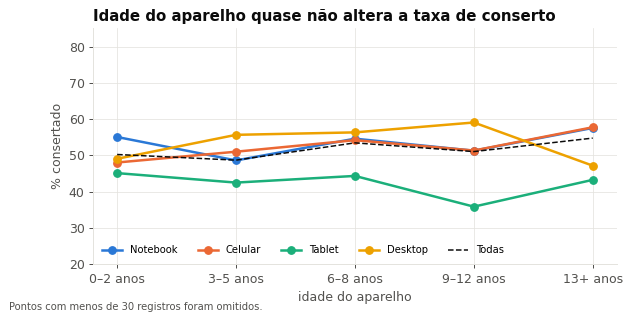

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig06_idade_conserto.png')

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for c in ORD_CAT:
    v = tx[c].where(nx[c] >= 30)
    ax.plot(ORD_FX, v, marker="o", markersize=6, color=g.COR_CATEGORIA[c], label=c)
ax.plot(ORD_FX, tx_all, color=g.TXT, lw=1.2, ls="--", label="Todas")
ax.set_ylim(20, 85); ax.set_ylabel("% consertado"); ax.set_xlabel("idade do aparelho")
ax.legend(ncol=5, fontsize=8, loc="lower left"); ax.set_title("Idade do aparelho quase não altera a taxa de conserto")
fig.text(0, -0.04, "Pontos com menos de 30 registros foram omitidos.", fontsize=8, color=g.TXT2)
g.salvar(fig, "fig06_idade_conserto")

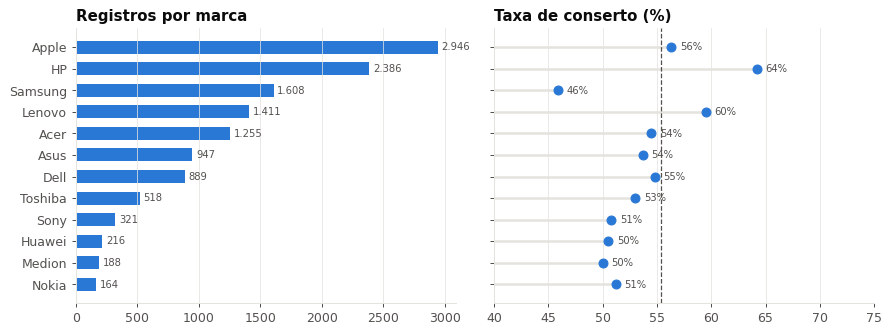

,n,taxa
marca,,
Apple,2946,56.3
HP,2386,64.2
Samsung,1608,45.9
Lenovo,1411,59.5
Acer,1255,54.5
Asus,947,53.7
Dell,889,54.8
Toshiba,518,53.0
Sony,321,50.8


In [13]:
# Marcas (conhecidas, >= 150 registros)
mc = reparos[reparos["marca"] != "Desconhecida"].groupby("marca").agg(n=("id", "count"), taxa=("consertado", "mean"))
mc = mc[mc["n"] >= 150].sort_values("n", ascending=False)
mc["taxa"] = (mc["taxa"] * 100).round(1)
R["marcas"] = mc.reset_index().to_dict("records"); R["pct_marca_desconhecida"] = round(float((reparos["marca"] == "Desconhecida").mean()*100), 1)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
axs[0].barh(mc.index, mc["n"], color=g.SERIES[0], height=.6); axs[0].invert_yaxis(); axs[0].set_title("Registros por marca"); axs[0].grid(axis="y", visible=False)
for i, v in enumerate(mc["n"]): axs[0].text(v + 30, i, f"{v:,}".replace(",", "."), va="center", fontsize=8, color=g.TXT2)
axs[1].hlines(range(len(mc)), 40, mc["taxa"], color=g.GRADE, lw=2); axs[1].plot(mc["taxa"], range(len(mc)), "o", color=g.SERIES[0], markersize=7)
axs[1].axvline(R["taxa_conserto_geral"], color=g.TXT2, ls="--", lw=1); axs[1].set_xlim(40, 75); axs[1].set_title("Taxa de conserto (%)")
for i, v in enumerate(mc["taxa"]): axs[1].text(v + .8, i, f"{v:.0f}%", va="center", fontsize=8, color=g.TXT2)
axs[1].grid(axis="y", visible=False)
fig.tight_layout(); g.salvar(fig, "fig07_marcas")
mc

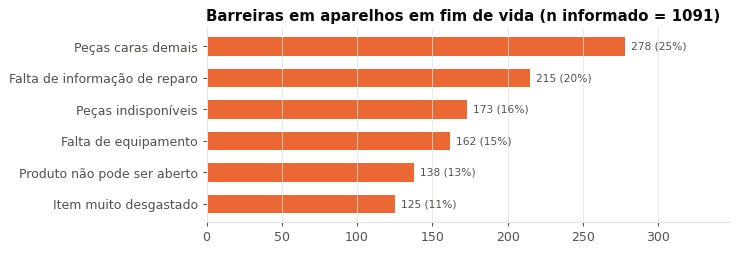

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig08_barreiras.png')

In [14]:
# Barreiras ao reparo (apenas fim de vida)
fv = reparos[reparos["status_reparo"] == "Fim de vida"]
bar = fv["barreira_reparo"].value_counts()
R["barreiras"] = bar.to_dict(); R["n_fim_vida"] = int(len(fv))
inf = bar.drop("Não informada")
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh(inf.index[::-1], inf.values[::-1], color=g.SERIES[1], height=.6); ax.grid(axis="y", visible=False)
for i, v in enumerate(inf.values[::-1]): ax.text(v + 4, i, f"{v} ({v/inf.sum()*100:.0f}%)", va="center", fontsize=8.5, color=g.TXT2)
ax.set_xlim(0, inf.max() * 1.25); ax.set_title(f"Barreiras em aparelhos em fim de vida (n informado = {inf.sum()})")
g.salvar(fig, "fig08_barreiras")

## 5. Base B — sintoma → tipo de falha

In [15]:
inf_b = falhas[falhas["categoria_falha"] != "Indeterminado"]
R["pct_indeterminado"] = round(float((falhas["categoria_falha"] == "Indeterminado").mean() * 100), 1)
R["pct_indeterminado_cat"] = (falhas.groupby("categoria")["categoria_falha"].apply(lambda s: (s == "Indeterminado").mean()*100).round(1)).to_dict()
hm = pd.crosstab(inf_b["categoria_falha"], inf_b["categoria"], normalize="columns").reindex(columns=ORD_CAT) * 100
hm = hm.loc[hm.mean(axis=1).sort_values(ascending=False).index]
R["falha_por_cat"] = hm.round(1).to_dict()
R["n_falhas_cat"] = inf_b["categoria"].value_counts().to_dict()
print("% indeterminado:", R["pct_indeterminado"], R["pct_indeterminado_cat"])
hm.round(1)

% indeterminado: 26.1 {'Celular': 19.6, 'Desktop': 42.5, 'Notebook': 27.9, 'Tablet': 20.2}


categoria,Notebook,Celular,Tablet,Desktop
categoria_falha,,,,
Tela,10.2,40.9,21.3,6.0
Software / sistema,20.9,9.2,21.9,23.0
Energia / bateria,12.5,15.8,23.3,21.8
Desempenho / superaquecimento,19.9,0.3,7.0,12.8
Conectores e portas,5.0,8.8,11.6,3.3
Inicialização (boot),6.8,1.9,4.7,9.0
Armazenamento,7.3,2.5,1.6,7.8
Placa / dano interno,5.2,1.4,1.9,9.3
Botões / teclado / touchpad,5.2,4.8,3.7,1.8


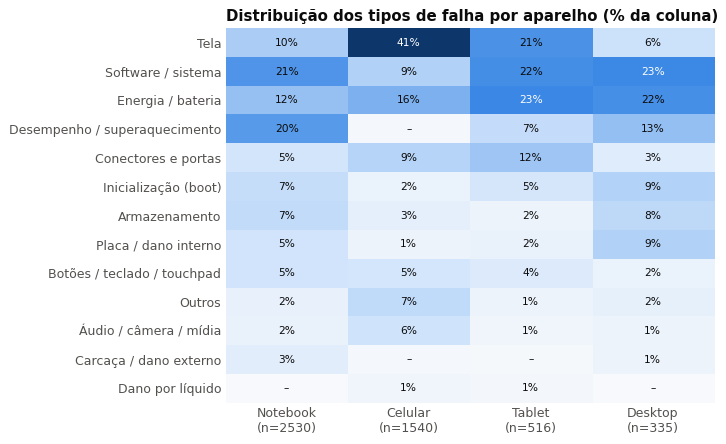

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig09_falhas_aparelho.png')

In [16]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("azul", ["#f7f9fc"] + g.AZUL_SEQ)
fig, ax = plt.subplots(figsize=(7, 5.4))
im = ax.imshow(hm.values, cmap=cmap, aspect="auto", vmin=0, vmax=max(40, hm.values.max()))
ax.set_xticks(range(len(ORD_CAT)), [f"{c}\n(n={R['n_falhas_cat'].get(c,0)})" for c in ORD_CAT]); ax.set_yticks(range(len(hm)), hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.values[i, j]
        ax.text(j, i, f"{v:.0f}%" if v >= 0.5 else "–", ha="center", va="center", fontsize=8.5, color="white" if v > 22 else g.TXT)
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Distribuição dos tipos de falha por aparelho (% da coluna)")
g.salvar(fig, "fig09_falhas_aparelho")

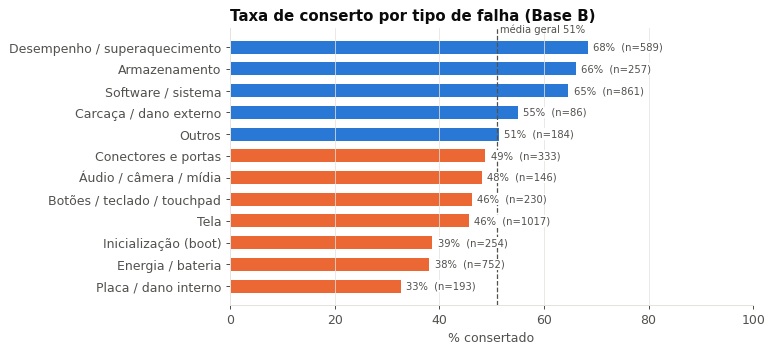

PosixPath('/home/claude/projeto-inforcell/reports/figures/fig10_conserto_falha.png')

In [17]:
tf = inf_b.groupby("categoria_falha").agg(n=("id_origem", "count"), taxa=("consertado", "mean")).query("n >= 40")
tf["taxa"] = (tf["taxa"] * 100).round(1); tf = tf.sort_values("taxa")
R["taxa_por_falha"] = tf.reset_index().to_dict("records")
fig, ax = plt.subplots(figsize=(7.5, 4))
media_b = falhas["consertado"].mean() * 100
ax.barh(tf.index, tf["taxa"], color=[g.SERIES[1] if v < media_b else g.SERIES[0] for v in tf["taxa"]], height=.6)
ax.axvline(media_b, color=g.TXT2, ls="--", lw=1); ax.text(media_b + .5, len(tf) - 0.35, f"média geral {media_b:.0f}%", fontsize=8, color=g.TXT2)
for i, (v, n) in enumerate(zip(tf["taxa"], tf["n"])): ax.text(v + 1, i, f"{v:.0f}%  (n={n})", va="center", fontsize=8, color=g.TXT2, bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
ax.set_xlim(0, 100); ax.grid(axis="y", visible=False); ax.set_xlabel("% consertado")
ax.set_title("Taxa de conserto por tipo de falha (Base B)")
R["taxa_media_b"] = round(media_b, 1)
g.salvar(fig, "fig10_conserto_falha")

### 5.1 O problema central da Inforcell nos dados: "não liga"
O documento da Etapa 1 cita *"o celular/computador não liga"* como exemplo de sintoma com várias causas possíveis. Verificamos isso buscando esse sintoma (em inglês, holandês, alemão e francês) na Base B.

Registros com sintoma 'não liga': 490 | categorias de falha distintas: 11


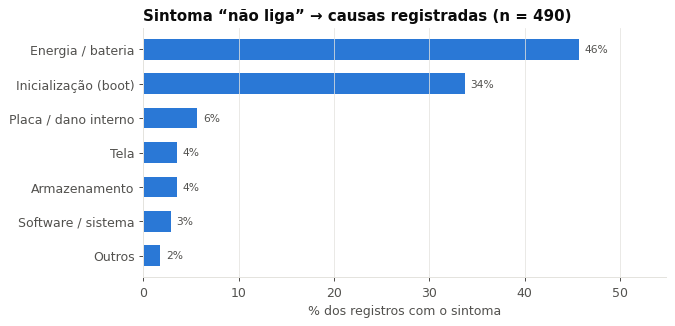

categoria_falha
Energia / bateria                45.7
Inicialização (boot)             33.7
Placa / dano interno              5.7
Tela                              3.5
Armazenamento                     3.5
Software / sistema                2.9
Outros                            1.8
Botões / teclado / touchpad       1.2
Conectores e portas               1.0
Desempenho / superaquecimento     0.8
Áudio / câmera / mídia            0.2

In [18]:
PADRAO_NAO_LIGA = re.compile(r"(?:won'?t|will not|does ?n[o']?t|doesnt|not|no|cannot|can'?t)\s+(?:turn|switch|power|boot|start)(?:ing|s)?\s*(?:on|up)?|dead|no power|"
                             r"gaat niet aan|start niet|geht nicht (?:mehr )?an|startet nicht|ne s'?allume|ne démarre", re.I)
nl = inf_b[inf_b["problema"].fillna("").str.contains(PADRAO_NAO_LIGA)]
dist_nl = nl["categoria_falha"].value_counts(normalize=True).mul(100).round(1)
R["nao_liga"] = {"n": int(len(nl)), "distribuicao": dist_nl.to_dict(), "n_categorias": int(nl["categoria_falha"].nunique())}
print("Registros com sintoma 'não liga':", len(nl), "| categorias de falha distintas:", nl["categoria_falha"].nunique())
fig, ax = plt.subplots(figsize=(7.5, 3.6))
d = dist_nl[dist_nl >= 1.5][::-1]
ax.barh(d.index, d.values, color=g.SERIES[0], height=.6); ax.grid(axis="y", visible=False)
for i, v in enumerate(d.values): ax.text(v + .6, i, f"{v:.0f}%", va="center", fontsize=8.5, color=g.TXT2)
ax.set_xlim(0, d.max() * 1.2); ax.set_xlabel("% dos registros com o sintoma")
ax.set_title(f"Sintoma “não liga” → causas registradas (n = {len(nl)})")
g.salvar(fig, "fig11_nao_liga")
dist_nl

In [19]:
# Termos mais característicos de cada tipo de falha (textos em inglês, log-odds com suavização)
from collections import Counter
en = inf_b[(inf_b["idioma"] == "en") & inf_b["problema"].notna() & ~inf_b["duplicata_texto"]]
STOP = set("the a an and or to of is was it on in for with not no be has have had but at as this that from by after so are were been its it's".split())
tok = lambda t: [w for w in re.findall(r"[a-z]{3,}", t.lower()) if w not in STOP]
glob = Counter(w for t in en["problema"] for w in tok(t)); Ng = sum(glob.values())
linhas = []
for cat, grp in en.groupby("categoria_falha"):
    if len(grp) < 40: continue
    c = Counter(w for t in grp["problema"] for w in tok(t)); Nc = sum(c.values())
    sc = {w: np.log((c[w] + 1) / (Nc + 1)) - np.log((glob[w] + 1) / (Ng + 1)) for w in c if c[w] >= 5}
    top = sorted(sc, key=sc.get, reverse=True)[:6]
    linhas.append({"categoria_falha": cat, "n_textos": len(grp), "termos": ", ".join(top)})
termos = pd.DataFrame(linhas).sort_values("n_textos", ascending=False)
R["termos"] = termos.to_dict("records")
termos

,categoria_falha,n_textos,termos
10,Tela,495,"touchscreen, digitiser, cracked, lcd, smashed, inverter"
9,Software / sistema,461,"firmware, printer, office, calendar, virus, app"
5,Energia / bateria,452,"quickly, supply, battery, circuit, charge, turn"
4,Desempenho / superaquecimento,312,"optimised, overheats, noisy, overheating, hot, running"
3,Conectores e portas,233,"micro, ports, sim, port, socket, jack"
1,Botões / teclado / touchpad,154,"keys, keyboard, button, key, home, trackpad"
6,Inicialização (boot),130,"booting, bios, boot, starting, start, won"
7,Outros,116,"iphone, water, damage, board, phone, user"
0,Armazenamento,115,"storage, hdd, hard, drive, memory, disk"
8,Placa / dano interno,103,"motherboard, dropped, board, water, damage, card"


## 6. Associação entre variáveis categóricas (V de Cramér)
Como quase todas as variáveis são categóricas, a correlação de Pearson não se aplica; usamos o **V de Cramér** (0 = nenhuma associação, 1 = associação perfeita).

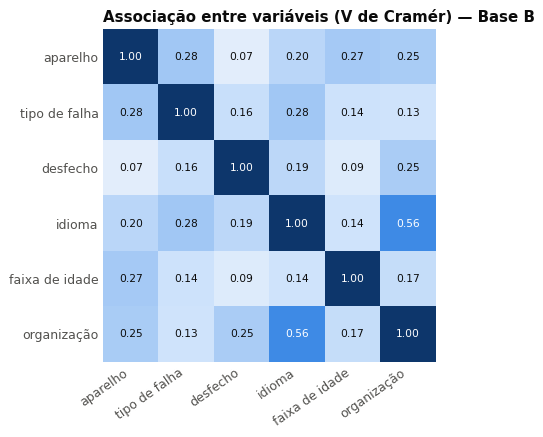

,aparelho,tipo de falha,desfecho,idioma,faixa de idade,organização
aparelho,1.00,0.28,0.07,0.20,0.27,0.25
tipo de falha,0.28,1.00,0.16,0.28,0.14,0.13
desfecho,0.07,0.16,1.00,0.19,0.09,0.25
idioma,0.20,0.28,0.19,1.00,0.14,0.56
faixa de idade,0.27,0.14,0.09,0.14,1.00,0.17
organização,0.25,0.13,0.25,0.56,0.17,1.00


In [20]:
b2 = falhas.copy()
b2["faixa_idade"] = pd.cut(b2["idade_anos"].astype(float), [-0.1, 2, 5, 8, 12, 100])
b2["tem_descricao"] = b2["tem_descricao"].astype(str)
vars_ = {"categoria": "aparelho", "categoria_falha": "tipo de falha", "status_reparo": "desfecho",
         "idioma": "idioma", "faixa_idade": "faixa de idade", "fonte": "organização"}
M = pd.DataFrame(index=vars_.values(), columns=vars_.values(), dtype=float)
for a, na in vars_.items():
    for b, nb in vars_.items():
        sub = b2[[a, b]].dropna()
        M.loc[na, nb] = 1.0 if a == b else prep.cramers_v(sub[a].astype(str), sub[b].astype(str))
R["cramer"] = M.round(2).to_dict()
fig, ax = plt.subplots(figsize=(6, 4.8))
im = ax.imshow(M.values.astype(float), cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(M)), M.columns, rotation=35, ha="right"); ax.set_yticks(range(len(M)), M.index)
for i in range(len(M)):
    for j in range(len(M)):
        v = M.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5, color="white" if v > .5 else g.TXT)
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Associação entre variáveis (V de Cramér) — Base B")
g.salvar(fig, "fig12_cramer")
M.round(2)

In [21]:
R["n_reparos"] = int(len(reparos)); R["n_falhas"] = int(len(falhas)); R["n_modelagem"] = int(falhas["apto_modelagem"].sum())
R["periodo"] = [str(reparos["data_evento"].min().date()), str(reparos["data_evento"].max().date())]
R["n_paises"] = int(reparos["pais"].nunique()); R["n_marcas"] = int(reparos["marca"].nunique())
R["pct_com_idade"] = round(float(reparos["idade_anos"].notna().mean()*100), 1)
R["pct_com_texto"] = round(float(reparos["tem_descricao"].mean()*100), 1)
R["modelagem_por_falha"] = falhas[falhas["apto_modelagem"]]["categoria_falha"].value_counts().to_dict()
json.dump(R, open("../../reports/resultados_eda.json", "w"), ensure_ascii=False, indent=1, default=str)
print("Resultados exportados:", len(R), "chaves")

Resultados exportados: 36 chaves
